# Análise dos experimentos

Lê `scripts/experiments/*/{runs,timeline,probe,summary}.csv` produzidos por
`scripts/experiment.py` e mostra tabelas e gráficos.

Pré-requisitos: `pip install pandas matplotlib jupyter`, e pelo menos um cenário
já executado (`scripts/experiment.py baseline --seeds 5`).

Execute as células em ordem. O DataFrame `runs` agrega todas as execuções;
`ttr` agrega os resumos de falha. Ajuste `SCENARIO` na última célula para
inspecionar outro diretório em `scripts/experiments/`.


In [12]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

try:
    from IPython.display import display
except ImportError:
    display = print

root = Path.cwd()
while not (root / "compose.yaml").exists() and root != root.parent:
    root = root.parent
EXP = root / "scripts" / "experiments"

frames = []
for f in sorted(EXP.glob("*/runs.csv")):
    df = pd.read_csv(f)
    if df.empty:
        continue
    df["experiment"] = f.parent.name
    frames.append(df)
runs = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()

print(f"{len(runs)} runs from {runs['experiment'].nunique() if not runs.empty else 0} experiments")
runs.head()


200 runs from 14 experiments


,tag,nodes,clients,ops,seed,duration_s,throughput_ops_s,p50_ms,p95_ms,p99_ms,retry_pct,attempts_per_op,attempts_p99,wrong_leader_pct,linearizable,experiment
0,baseline,3,8,1600,1,0.915,1747.90,4.320,6.889,8.309,0.0,1.0,1.0,0.0,ok,baseline
1,baseline,3,8,1600,2,1.004,1594.33,4.499,8.016,17.582,0.0,1.0,1.0,0.0,ok,baseline
2,baseline,3,8,1600,3,0.960,1667.35,4.520,7.005,9.280,0.0,1.0,1.0,0.0,ok,baseline
3,baseline,3,8,1600,4,0.949,1686.63,4.400,6.686,9.899,0.0,1.0,1.0,0.0,ok,baseline
4,baseline,3,8,1600,5,0.961,1664.52,4.509,6.871,8.999,0.0,1.0,1.0,0.0,ok,baseline


In [13]:
METRICS = ["throughput_ops_s", "p50_ms", "p95_ms", "p99_ms", "retry_pct", "attempts_per_op"]

if runs.empty:
    print("no experiments yet: run scripts/experiment.py first")
else:
    table = runs.groupby(["experiment", "tag"])[METRICS].agg(["mean", "std"]).round(2)
    display(table)


throughput_ops_s          p50_ms        \
                                            mean     std    mean   std   
experiment     tag                                                       
baseline       baseline                  1667.68   49.64    4.46  0.07   
kill-leader-n3 kill-after                1652.75   75.45    4.55  0.24   
               kill-during               1797.86  109.16    4.13  0.07   
kill-leader-n5 kill-after                1325.62  156.45    5.74  0.65   
               kill-during               1454.15   98.39    5.20  0.40   
kill-leader-n7 kill-after                1029.19  149.15    7.37  1.02   
               kill-during               1107.95  151.52    6.73  0.80   
netem-d100ms   netem-100ms-0%              25.93    0.07  301.83  0.06   
netem-d50ms    netem-50ms-0%               50.43    1.70  152.70  1.63   
netem-l2pct    netem-0ms-2%               594.23  106.25    1.98  0.31   
netem-l5pct    netem-0ms-5%               238.34   54.48    1.83  0.14   
partition-n3   partition-after           1710.13   64.05    4.38  0.11   
               partition-during          1753.68  129.95    4.20  0.08   
partition-n5   partition-after           1280.37   98.79    5.90  0.51   
               partition-during          1412.02  114.13    5.27  0.48   
partition-n7   partition-after            940.61   95.66    8.00  0.67   
               partition-during          1011.38   72.54    7.41  0.51   
sweep-n3       n3                        1685.72   96.58    4.48  0.27   
sweep-n5       n5                        1207.19   83.68    5.99  0.23   
sweep-n7       n7                         949.45   72.95    7.87  0.56   

                                 p95_ms         p99_ms         retry_pct  \
                                   mean    std    mean     std      mean   
experiment     tag                                                         
baseline       baseline            7.11   0.38   11.38    5.11      0.00   
kill-leader-n3 kill-after          7.27   0.36    9.72    2.13      0.30   
               kill-during         6.44   0.22    9.10    3.34      0.20   
kill-leader-n5 kill-after          9.18   1.19   12.51    4.55      0.35   
               kill-during         8.17   0.56   12.17    4.33      0.30   
kill-leader-n7 kill-after         12.10   1.70   18.10    5.29      0.35   
               kill-during        11.02   1.60   16.62    8.36      0.35   
netem-d100ms   netem-100ms-0%    304.38   0.83  312.99    3.58      0.50   
netem-d50ms    netem-50ms-0%     175.19  23.60  204.26   47.59      0.00   
netem-l2pct    netem-0ms-2%        4.91   0.86  210.17    1.03      0.50   
netem-l5pct    netem-0ms-5%      200.06  22.59  487.18  292.51      0.49   
partition-n3   partition-after     6.96   0.36   10.40    4.09      0.40   
               partition-during    6.63   0.39    9.74    3.77      0.35   
partition-n5   partition-after     9.47   0.71   12.49    2.23      0.35   
               partition-during    8.45   0.82   11.60    2.94      0.40   
partition-n7   partition-after    13.20   1.22   18.49    5.33      0.45   
               partition-during   12.44   0.84   17.39    3.87      0.45   
sweep-n3       n3                  7.10   0.43   10.18    2.58      0.50   
sweep-n5       n5                 10.36   1.55   15.54    7.42      0.50   
sweep-n7       n7                 13.24   1.38   18.28    4.23      0.50   

                                      attempts_per_op        
                                  std            mean   std  
experiment     tag                                           
baseline       baseline          0.00            1.00  0.00  
kill-leader-n3 kill-after        0.26            1.00  0.00  
               kill-during       0.26            1.00  0.00  
kill-leader-n5 kill-after        0.24            1.01  0.01  
               kill-during       0.26            1.01  0.01  
kill-leader-n7 kill-after        0.24            1.01  0.01  
               kill-du

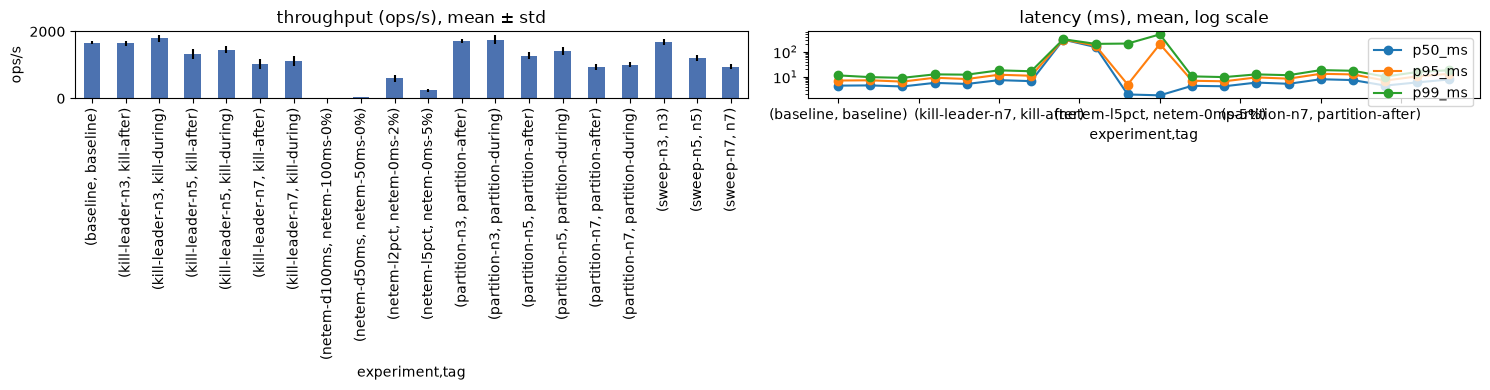

In [14]:
if not runs.empty:
    fig, axes = plt.subplots(1, 2, figsize=(15, 4))

    mean = runs.groupby(["experiment", "tag"])["throughput_ops_s"].mean()
    std = runs.groupby(["experiment", "tag"])["throughput_ops_s"].std().fillna(0)
    mean.plot.bar(yerr=std, ax=axes[0], color="#4C72B0")
    axes[0].set_title("throughput (ops/s), mean ± std")
    axes[0].set_ylabel("ops/s")

    for m in ["p50_ms", "p95_ms", "p99_ms"]:
        runs.groupby(["experiment", "tag"])[m].mean().plot(ax=axes[1], marker="o", label=m)
    axes[1].set_yscale("log")
    axes[1].set_title("latency (ms), mean, log scale")
    axes[1].legend()

    plt.tight_layout()
    plt.show()

,seed,fault_unix_ms,time_to_elect_ms,ttr_service_ms,ttr_replica_ms,pre_term,new_term,converged,fault_cmd_ms,heal_unix_ms,experiment
0,1,1794549096428,792,2215,602,1,2,True,331,1794549099439,kill-leader-n3
1,2,1794549103522,866,2224,917,2,3,True,370,1794549106336,kill-leader-n3
2,3,1794549110784,760,745,561,3,4,True,364,1794549113525,kill-leader-n3
3,4,1794549120845,754,2250,333,4,5,True,403,1794549123670,kill-leader-n3
4,5,1794549127530,766,2281,439,5,6,True,445,1794549130222,kill-leader-n3
5,6,1794549134180,815,2224,560,6,7,True,415,1794549136928,kill-leader-n3
6,7,1794549141077,763,2197,604,7,8,True,315,1794549143903,kill-leader-n3
7,8,1794549148008,4136,5504,548,8,9,True,303,1794549154167,kill-leader-n3
8,9,1794549158455,2026,2208,675,9,11,True,328,1794549162459,kill-leader-n3
9,10,1794549166662,755,2206,603,11,12,True,336,1794549169492,kill-leader-n3


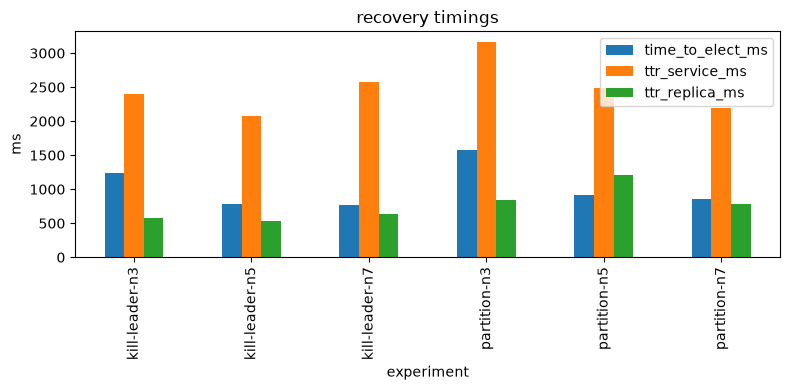

In [15]:
NUMERIC = ["time_to_elect_ms", "ttr_service_ms", "ttr_replica_ms"]

ttr_frames = []
for f in sorted(EXP.glob("*/summary.csv")):
    df = pd.read_csv(f)
    if set(NUMERIC).issubset(df.columns):
        df["experiment"] = f.parent.name
        ttr_frames.append(df)
ttr = pd.concat(ttr_frames, ignore_index=True) if ttr_frames else pd.DataFrame()

if ttr.empty:
    print("no fault runs yet (kill-leader / partition)")
else:
    for col in NUMERIC:
        ttr[col] = pd.to_numeric(ttr[col], errors="coerce")
    display(ttr)
    mean = ttr.groupby("experiment")[NUMERIC].mean()
    ax = mean.plot.bar(figsize=(8, 4))
    ax.set_ylabel("ms")
    ax.set_title("recovery timings")
    plt.tight_layout()
    plt.show()

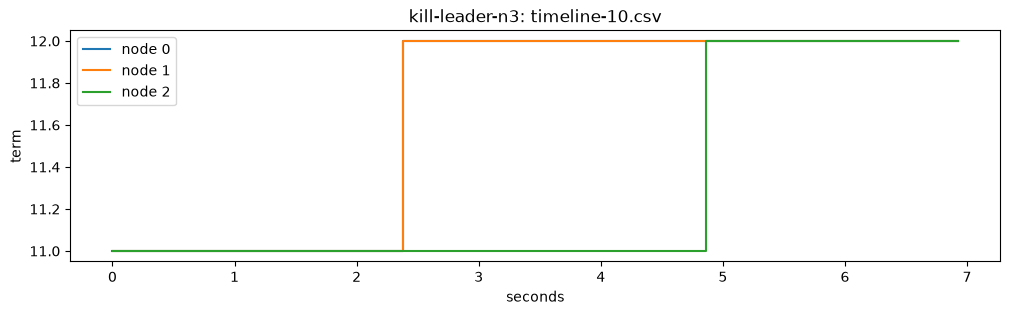

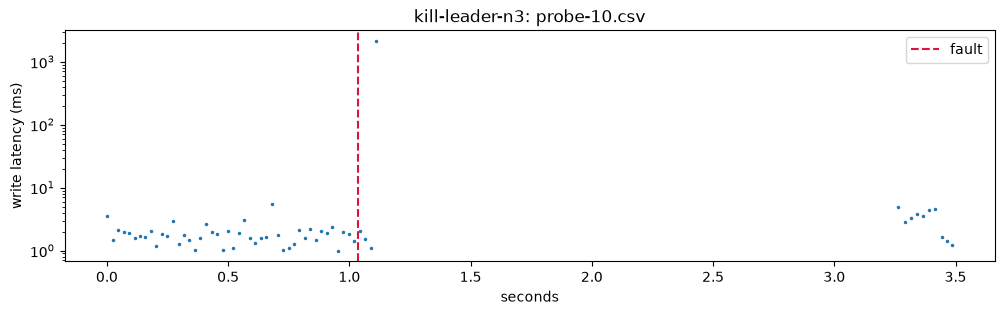

In [16]:
SCENARIO = "kill-leader-n3"   # any directory under scripts/experiments/

def latest_per_seed(prefix):
    """Newest `prefix-<seed>.csv` (fallback: `prefix.csv`), or None."""
    files = sorted((EXP / SCENARIO).glob(f"{prefix}-[0-9]*.csv"),
                   key=lambda p: int(p.stem.split("-")[1]))
    if files:
        return files[-1]
    plain = EXP / SCENARIO / f"{prefix}.csv"
    return plain if plain.exists() else None

tl_path = latest_per_seed("timeline")
if tl_path:
    tl = pd.read_csv(tl_path)
    tl["t_s"] = (tl["t_ms"] - tl["t_ms"].min()) / 1000
    fig, ax = plt.subplots(figsize=(12, 3))
    for node, g in tl.groupby("node"):
        ax.step(g["t_s"], g["term"], where="post", label=f"node {node}")
    ax.set(xlabel="seconds", ylabel="term", title=f"{SCENARIO}: {tl_path.name}")
    ax.legend()
    plt.show()

pr_path = latest_per_seed("probe")
if pr_path:
    pr = pd.read_csv(pr_path)
    pr["t_s"] = (pr["start_ns"] - pr["start_ns"].min()) / 1e9
    fig, ax = plt.subplots(figsize=(12, 3))
    ax.plot(pr["t_s"], pr["lat_ms"], ".", ms=3)

    sm_path = EXP / SCENARIO / "summary.csv"
    if sm_path.exists():
        sm = pd.read_csv(sm_path)
        seed = int(pr_path.stem.split("-")[1]) if "-" in pr_path.stem else None
        row = sm[sm["seed"] == seed] if seed is not None and "seed" in sm.columns else sm.iloc[:1]
        if not row.empty and "fault_unix_ms" in row.columns \
                and pd.notna(row["fault_unix_ms"].iloc[0]):
            fault_s = (row["fault_unix_ms"].iloc[0] * 1e6 - pr["start_ns"].min()) / 1e9
            ax.axvline(fault_s, color="crimson", ls="--", label="fault")
            ax.legend()

    ax.set_yscale("log")
    ax.set(xlabel="seconds", ylabel="write latency (ms)", title=f"{SCENARIO}: {pr_path.name}")
    plt.show()

## Como ler

* `baseline` deve ter `retry_pct ~ 0` e zero mudanças de líder; qualquer coisa
  diferente indica contenção ou timeouts agressivos.
* Em `netem`, o throughput cai e p99 sobe, mas `linearizable` continua `ok`.
* Em `kill-leader`, `time_to_elect` deve ficar perto do `ElectionTimeout`
  (500 ms + jitter) e `ttr_service` inclui o timeout HTTP do cliente (~2 s).
* `ttr_replica` cresce com o atraso do nó e com o tamanho do log; com
  `MAX_RAFT_STATE` baixo o nó atrasado é recuperado por `InstallSnapshot`.
* Term/leader no timeline mostrando `leader_id = -1` e termos crescendo sem
  parar é o problema de *disruptive server* descrito em `scripts/README.md`.


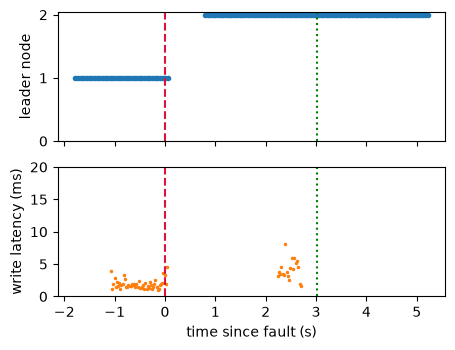

seed 1: fault at 0 s (dashed), heal at 3.0 s (dotted)


In [17]:
# Report figure: the kill-leader-n3 seed with the median time-to-elect
kill = EXP / "kill-leader-n3"
sm = pd.read_csv(kill / "summary.csv")
row = sm.sort_values("time_to_elect_ms").iloc[len(sm) // 2]
seed, fault = int(row["seed"]), row["fault_unix_ms"]
heal = (row["heal_unix_ms"] - fault) / 1000
tl = pd.read_csv(kill / f"timeline-{seed}.csv")
pr = pd.read_csv(kill / f"probe-{seed}.csv")
tl["t"] = (tl["t_ms"] - fault) / 1000
pr["t"] = (pr["start_ns"] / 1e6 - fault) / 1000
lead = tl[tl["is_leader"]]

fig, axes = plt.subplots(2, 1, figsize=(5, 3.7), sharex=True)
axes[0].plot(lead["t"], lead["node"], ".", color="C0")
axes[0].set(ylabel="leader node", yticks=sorted(tl["node"].unique()))
axes[1].plot(pr["t"], pr["lat_ms"], ".", ms=3, color="C1")
axes[1].set(ylabel="write latency (ms)", xlabel="time since fault (s)")
axes[1].set_ylim(0, 20)
for ax in axes:
    ax.axvline(0, color="crimson", ls="--")
    ax.axvline(heal, color="green", ls=":")

figs = root / "docs" / "report" / "figs"
figs.mkdir(parents=True, exist_ok=True)
fig.savefig(figs / "kill-leader-n3.pdf", bbox_inches="tight")
plt.show()
print(f"seed {seed}: fault at 0 s (dashed), heal at {heal:.1f} s (dotted)")

## Tabelas do relatório

Estas células reproduzem, a partir dos CSVs, as três tabelas da Seção de
Resultados (`tab:perf`, `tab:recovery` e `tab:stability` em
`docs/report/report.tex`). Rode-as depois de `scripts/run_experiments.py` e
copie as linhas impressas para o `.tex` (ou compare com o que está lá): os
valores acompanham os dados, nada é digitado à mão.


In [18]:
# tab:perf — throughput e latência sem falhas (medianas por seed)
import numpy as np

PERF_SPECS = [
    ("$N=3$", 3, "baseline", "baseline"),
    ("$N=5$", 5, "sweep-n5", "n5"),
    ("$N=7$", 7, "sweep-n7", "n7"),
    ("50\\,ms delay", 3, "netem-d50ms", None),
    ("100\\,ms delay", 3, "netem-d100ms", None),
    ("2\\,\\% loss", 3, "netem-l2pct", None),
    ("5\\,\\% loss", 3, "netem-l5pct", None),
]

def pick(experiment, tag=None):
    df = runs[runs["experiment"] == experiment]
    return df if tag is None else df[df["tag"] == tag]

perf = pd.DataFrame([{
    "config": c, "N": n,
    "ops/s": pick(e, t)["throughput_ops_s"].median(),
    "p50_ms": pick(e, t)["p50_ms"].median(),
    "p95_ms": pick(e, t)["p95_ms"].median(),
    "p99_ms": pick(e, t)["p99_ms"].median(),
} for c, n, e, t in PERF_SPECS])

display(perf.round(1))
def ms(v):
    """Uma casa decimal abaixo de 100 ms, inteiro acima (como no relatório)."""
    return f"{v:.0f}" if v >= 100 else f"{v:.1f}"

print("% linhas de tab:perf")
for _, r in perf.iterrows():
    print(f"{r['config']:18s} & {r['N']} & {r['ops/s']:.0f} & "
          f"{ms(r['p50_ms'])} & {ms(r['p95_ms'])} & {ms(r['p99_ms'])} \\\\")


,config,N,ops/s,p50_ms,p95_ms,p99_ms
0,$N=3$,3,1671.0,4.5,7.1,9.1
1,$N=5$,5,1183.5,5.9,9.8,14.3
2,$N=7$,7,954.1,7.8,13.2,18.2
3,"50\,ms delay",3,51.4,151.7,164.5,186.8
4,"100\,ms delay",3,26.0,301.8,304.1,312.4
5,"2\,\% loss",3,578.6,1.9,5.0,209.9
6,"5\,\% loss",3,222.0,1.8,207.2,374.3


% linhas de tab:perf
$N=3$              & 3 & 1671 & 4.5 & 7.1 & 9.1 \\
$N=5$              & 5 & 1184 & 5.9 & 9.8 & 14.3 \\
$N=7$              & 7 & 954 & 7.8 & 13.2 & 18.2 \\
50\,ms delay       & 3 & 51 & 152 & 165 & 187 \\
100\,ms delay      & 3 & 26 & 302 & 304 & 312 \\
2\,\% loss         & 3 & 579 & 1.9 & 5.0 & 210 \\
5\,\% loss         & 3 & 222 & 1.8 & 207 & 374 \\


In [19]:
# tab:recovery — tempo de recuperação: média ± desvio padrão por seed
TTR_COLS = ["time_to_elect_ms", "ttr_service_ms", "ttr_replica_ms"]

FAULT_SPECS = [
    ("Crash", 3, "kill-leader-n3"),
    ("Crash", 5, "kill-leader-n5"),
    ("Crash", 7, "kill-leader-n7"),
    ("Partition", 3, "partition-n3"),
    ("Partition", 5, "partition-n5"),
    ("Partition", 7, "partition-n7"),
]

rows = []
for fault, n, e in FAULT_SPECS:
    g = ttr[ttr["experiment"] == e]
    row = {"fault": fault, "N": n}
    for c in TTR_COLS:
        row[c] = g[c].mean()
        row[c + "_sd"] = g[c].std(ddof=1)   # amostral, como no relatório
    rows.append(row)
rec = pd.DataFrame(rows)

display(rec.round(0))
print("% linhas de tab:recovery (média ± desvio padrão)")
for _, r in rec.iterrows():
    cells = " & ".join(f"{r[c]:.0f} $\\pm$ {r[c + '_sd']:.0f}" for c in TTR_COLS)
    print(f"{r['fault']:10s} & {r['N']} & {cells} \\\\")


,fault,N,time_to_elect_ms,time_to_elect_ms_sd,ttr_service_ms,ttr_service_ms_sd,ttr_replica_ms,ttr_replica_ms_sd
0,Crash,3,1243.0,1089.0,2405.0,1184.0,584.0,152.0
1,Crash,5,784.0,36.0,2081.0,461.0,526.0,313.0
2,Crash,7,774.0,47.0,2574.0,1050.0,633.0,270.0
3,Partition,3,1571.0,1380.0,3162.0,1611.0,849.0,447.0
4,Partition,5,911.0,63.0,2494.0,1054.0,1212.0,1129.0
5,Partition,7,859.0,30.0,2187.0,27.0,780.0,267.0


% linhas de tab:recovery (média ± desvio padrão)
Crash      & 3 & 1243 $\pm$ 1089 & 2405 $\pm$ 1184 & 584 $\pm$ 152 \\
Crash      & 5 & 784 $\pm$ 36 & 2081 $\pm$ 461 & 526 $\pm$ 313 \\
Crash      & 7 & 774 $\pm$ 47 & 2574 $\pm$ 1050 & 633 $\pm$ 270 \\
Partition  & 3 & 1571 $\pm$ 1380 & 3162 $\pm$ 1611 & 849 $\pm$ 447 \\
Partition  & 5 & 911 $\pm$ 63 & 2494 $\pm$ 1054 & 1212 $\pm$ 1129 \\
Partition  & 7 & 859 $\pm$ 30 & 2187 $\pm$ 27 & 780 $\pm$ 267 \\


In [20]:
# tab:stability — custo de retry e churn de líder (medianas por seed)
STAB_SPECS = [
    ("$N=3$", "baseline", "baseline"),
    ("50\\,ms delay", "netem-d50ms", None),
    ("100\\,ms delay", "netem-d100ms", None),
    ("2\\,\\% loss", "netem-l2pct", None),
    ("5\\,\\% loss", "netem-l5pct", None),
    ("Crash, $N=3$", "kill-leader-n3", None),
    ("Crash, $N=5$", "kill-leader-n5", None),
    ("Crash, $N=7$", "kill-leader-n7", None),
    ("Partition, $N=3$", "partition-n3", None),
    ("Partition, $N=5$", "partition-n5", None),
    ("Partition, $N=7$", "partition-n7", None),
]

def leader_changes(experiment):
    """Mudanças de líder por seed, a partir dos timeline-*.csv."""
    per_seed = []
    for f in sorted(EXP.glob(f"{experiment}/timeline*.csv")):
        tl = pd.read_csv(f)
        lead = tl[tl["is_leader"].astype(str).str.lower() == "true"]
        per_seed.append(sum(a != b for a, b in zip(lead["node"], lead["node"][1:])))
    return per_seed

rows = []
for label, experiment, tag in STAB_SPECS:
    g = pick(experiment, tag) if tag else pick(experiment)
    ch = leader_changes(experiment)
    rows.append({
        "config": label,
        "retry_pct": g["retry_pct"].median(),
        "attempts_op": g["attempts_per_op"].median(),
        "wrong_leader_pct": g["wrong_leader_pct"].median(),
        "changes_median": np.median(ch) if ch else 0,
        "changes_max": max(ch) if ch else 0,
    })
stab = pd.DataFrame(rows)

display(stab.round(2))
print("% linhas de tab:stability")
for _, r in stab.iterrows():
    print(f"{r['config']:18s} & {r['retry_pct']:.1f} & {r['attempts_op']:.2f} & "
          f"{r['wrong_leader_pct']:.1f} & {int(r['changes_median'])} ({int(r['changes_max'])}) \\\\")


,config,retry_pct,attempts_op,wrong_leader_pct,changes_median,changes_max
0,$N=3$,0.00,1.00,0.00,0.0,0
1,"50\,ms delay",0.00,1.00,0.00,0.0,0
2,"100\,ms delay",0.50,1.00,0.50,0.0,0
3,"2\,\% loss",0.50,1.00,0.50,0.0,0
4,"5\,\% loss",0.50,1.00,0.66,0.0,1
5,"Crash, $N=3$",0.25,1.00,0.25,1.0,1
6,"Crash, $N=5$",0.50,1.01,0.99,1.0,1
7,"Crash, $N=7$",0.50,1.01,1.48,1.0,1
8,"Partition, $N=3$",0.50,1.00,0.50,1.0,11
9,"Partition, $N=5$",0.50,1.00,0.50,1.0,2


% linhas de tab:stability
$N=3$              & 0.0 & 1.00 & 0.0 & 0 (0) \\
50\,ms delay       & 0.0 & 1.00 & 0.0 & 0 (0) \\
100\,ms delay      & 0.5 & 1.00 & 0.5 & 0 (0) \\
2\,\% loss         & 0.5 & 1.00 & 0.5 & 0 (0) \\
5\,\% loss         & 0.5 & 1.00 & 0.7 & 0 (1) \\
Crash, $N=3$       & 0.2 & 1.00 & 0.2 & 1 (1) \\
Crash, $N=5$       & 0.5 & 1.01 & 1.0 & 1 (1) \\
Crash, $N=7$       & 0.5 & 1.01 & 1.5 & 1 (1) \\
Partition, $N=3$   & 0.5 & 1.00 & 0.5 & 1 (11) \\
Partition, $N=5$   & 0.5 & 1.00 & 0.5 & 1 (2) \\
Partition, $N=7$   & 0.5 & 1.01 & 1.0 & 1 (7) \\


## Figura: throughput e latência ao redor da falha de líder

Esta célula desenha, para um único seed de um cenário de falha de líder, o
*throughput* e a *latência* ao longo do tempo, com três marcas verticais: o
instante da desconexão do líder, a eleição do novo líder e o reingresso do
líder antigo. O throughput é a taxa de escritas completadas pela *probe*
(janela deslizante de 0.5 s), então ele é um indicador de disponibilidade e
não o throughput máximo do cluster (a probe escreve uma chave por vez).


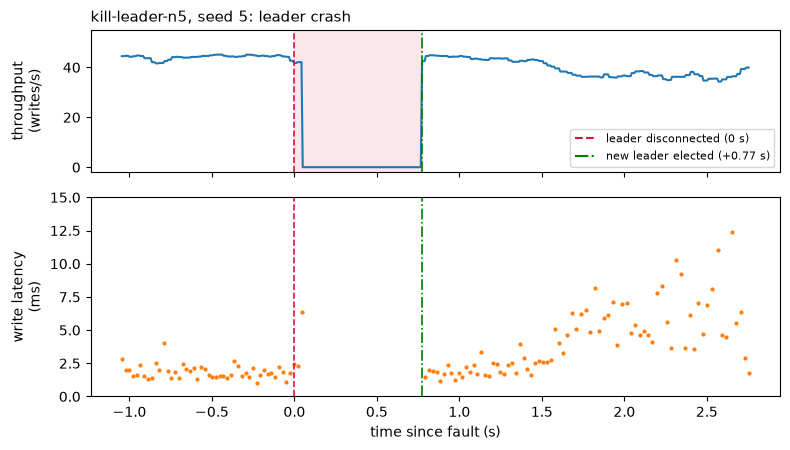

In [22]:
# Figura de linha do tempo de uma falha de líder. Troque SCENARIO / SEED
# para inspecionar outro estudo (kill-leader-n3/5/7 ou partition-n3/5/7).
SCENARIO = "kill-leader-n5"
SEED = 5

sm = pd.read_csv(EXP / SCENARIO / "summary.csv")
row = sm[sm.seed == SEED].iloc[0]
pr = pd.read_csv(EXP / SCENARIO / f"probe-{SEED}.csv")

fault = row["fault_unix_ms"]

# instantes dos eventos, em segundos relativos à falha
t_elect = row["time_to_elect_ms"] / 1000
t_svc = row["ttr_service_ms"] / 1000   # primeira escrita completada após a falha

# throughput instantâneo (1/dt entre conclusões, 0 durante o bloqueio da falha)
pr = pr.sort_values("end_ns").reset_index(drop=True)
pr["t_end"] = (pr["end_ns"] / 1e6 - fault) / 1000
dt = pr["t_end"].diff()
inst = (1.0 / dt.where(dt <= 0.15)).rolling(5, min_periods=1, center=True).mean()
t_grid = np.linspace(pr["t_end"].iloc[0], pr["t_end"].iloc[-1], 500)
idx = np.searchsorted(pr["t_end"], t_grid, side="right").clip(1, len(pr) - 1)
rate = np.where(dt.to_numpy()[idx] > 0.15, 0.0, inst.to_numpy()[idx])

from matplotlib.lines import Line2D

fig, axes = plt.subplots(
    2, 1, figsize=(8, 4.6), sharex=True,
    gridspec_kw={"height_ratios": [1, 1.4]})

# painel superior: throughput (escritas/s completadas pela probe)
ax = axes[0]
ax.plot(t_grid, rate, color="C0", lw=1.5)
ax.axvspan(0, t_svc, color="crimson", alpha=0.10)          # janela de indisponibilidade
ax.set_ylim(-2, 55)
ax.set_ylabel("throughput\n(writes/s)")
ax.set_title(f"{SCENARIO}, seed {SEED}: leader crash", loc="left", fontsize=11)

# painel inferior: latência de cada escrita (escala linear, foco em 0-20 ms)
ax = axes[1]
ax.plot(pr["t_end"], pr["lat_ms"], ".", ms=4, color="C1")
ax.set_ylim(0, 15)
ax.set_ylabel("write latency\n(ms)")
ax.set_xlabel("time since fault (s)")

# as marcas verticais
for ax in axes:
    ax.axvline(0,       color="crimson", ls="--", lw=1.2)   # líder desconectado
    ax.axvline(t_elect, color="green",  ls="-.", lw=1.2)   # novo líder eleito

handles = [
    Line2D([], [], color="crimson", ls="--", label="leader disconnected (0 s)"),
    Line2D([], [], color="green",  ls="-.", label=f"new leader elected (+{t_elect:.2f} s)"),
]
axes[0].legend(handles=handles, loc="lower right", fontsize=8)

fig.align_ylabels(axes)
fig.tight_layout()

figs = root / "docs" / "report" / "figs"
figs.mkdir(parents=True, exist_ok=True)
fig.savefig(figs / "leader-fault-timeline.pdf", bbox_inches="tight")
plt.show()
